# Загрузка данных и импорт функций
Пришлось добавить заголовки, чтобы всё работало

In [1]:
import requests

URL_LAUREATES = 'https://api.nobelprize.org/2.1/laureates?limit=1200'

headers = {
    'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36'
}

laureates_response = requests.get(URL_LAUREATES, headers=headers)

if laureates_response.status_code == 200:
    laureates = laureates_response.json()
    print(f"Успешно загружено {len(laureates.get('laureates', []))} записей")
else:
    print(f"Ошибка! Статус код: {laureates_response.status_code}")
    print(f"Ответ сервера: {laureates_response.text[:500]}")

Успешно загружено 1028 записей


# Импорт функций из первого этапа проекта

In [2]:
from laureates_configs import process_orgs, process_persons


def get_laureate_data(laureate):
    if 'knownName' in laureate:
        return process_persons(laureate)
    elif 'orgName' in laureate:
        return process_orgs(laureate)
    else:
        return {'id': laureate.get('id'), 'type_': 'unknown'}


laureates_data = []

for laureate in laureates['laureates']:
    laureates_data.append(get_laureate_data(laureate))

# Технический анализ данных
Проверим, сколько всего записей, все ли поля заполнены, есть ли пропуски, нет ли дубликатов по id

In [3]:
total_records = len(laureates_data)
print(f"всего записей: {total_records}")
print()

all_keys = set()
for record in laureates_data:
    all_keys.update(record.keys())

print("проверка заполненности полей:")
print(f"{'поле':<25} {'заполнено':<12} {'пропуски':<12} {'доля пропусков':<15}")
print("-" * 70)

missing_values = {}

for key in sorted(all_keys):
    filled = sum(1 for r in laureates_data if key in r and r[key] is not None)
    missing = total_records - filled
    missing_pct = (missing / total_records) * 100 if total_records > 0 else 0

    missing_values[key] = missing

    print(f"{key:<25} {filled:<12} {missing:<12} {missing_pct:<15.2f}%")

print()

ids = [r['id'] for r in laureates_data if 'id' in r and r['id'] is not None]

if ids:
    min_id = min(ids)
    max_id = max(ids)

    print(f"Анализ поля id")
    print(f"минимальный id: {min_id}")
    print(f"максимальный id: {max_id}")

    unique_ids = set(ids)
    duplicates = len(ids) - len(unique_ids)
    print(f"дубликатов id: {duplicates}")

    sorted_ids = sorted(unique_ids)
    gaps = []
    for i in range(1, len(sorted_ids)):
        diff = sorted_ids[i] - sorted_ids[i-1]
        if diff > 1:
            gaps.append((sorted_ids[i-1], sorted_ids[i], diff))

    print(f"кол-во разрывов в последовательности id: {len(gaps)}")

всего записей: 1028

проверка заполненности полей:
поле                      заполнено    пропуски     доля пропусков 
----------------------------------------------------------------------
birth_year                1000         28           2.72           %
country_birth             997          31           3.02           %
country_founded           24           1004         97.67          %
country_now               1021         7            0.68           %
founded_year              27           1001         97.37          %
gender                    1000         28           2.72           %
id                        1028         0            0.00           %
name                      1028         0            0.00           %
prizes_relevant           1028         0            0.00           %
type_                     1028         0            0.00           %

Анализ поля id
минимальный id: 1
максимальный id: 1070
дубликатов id: 0
кол-во разрывов в последовательности id: 24


# Вспомогательные функции для EDA
По заданию нужно создать переиспользуемые функции для работы с данными.

In [4]:
def filter_by_condition(data, key, value):
    result = []
    for record in data:
        if key in record and record[key] == value:
            result.append(record)
    return result


def group_by(data, keys):
    groups = {}

    for record in data:
        key_values = tuple(record.get(k) for k in keys)

        if key_values not in groups:
            groups[key_values] = []
        groups[key_values].append(record)

    return groups


def calculate_mean(data, key):
    values = [r[key] for r in data if key in r and r[key] is not None]

    if not values:
        return None

    return sum(values) / len(values)


def calculate_median(data, key):
    values = sorted([r[key] for r in data if key in r and r[key] is not None])

    if not values:
        return None

    n = len(values)
    mid = n // 2

    if n % 2 == 0:
        return (values[mid - 1] + values[mid]) / 2
    else:
        return values[mid]


def get_top_n(data, key, n=10, reverse=True):
    filtered = [r for r in data if key in r and r[key] is not None]

    sorted_data = sorted(filtered, key=lambda x: x[key], reverse=reverse)

    return sorted_data[:n]

# 2.1 Топ-статистика по странам

**Вопросы для анализа:**
- Какие страны дали больше всего лауреатов?
- Как распределяются лауреаты по категориям в разных странах?

Для поиска ответов на вопросы:
1. Сгруппирую лауреатов по стране рождения
2. Посчитаю количество в каждой группе
3. Выведу топ-5 стран
4. Повторю для каждой категории премии

In [5]:
persons_only = [r for r in laureates_data if r.get('type_') == 'person']

print(f"всего лауреатов-людей: {len(persons_only)}")
print()

country_groups = group_by(persons_only, ['country_birth'])

country_counts = []
for country, records in country_groups.items():
    country_name = country[0]
    if country_name is not None:
        country_counts.append({
            'country': country_name,
            'count': len(records)
        })

country_counts_sorted = sorted(country_counts, key=lambda x: x['count'], reverse=True)

print("топ-10 стран по количеству лауреатов:")
print(f"{'место':<6} {'страна':<20} {'количество':<12}")
print("-" * 40)

for i, record in enumerate(country_counts_sorted[:10], 1):
    print(f"{i:<6} {record['country']:<20} {record['count']:<12}")

всего лауреатов-людей: 1000

топ-10 стран по количеству лауреатов:
место  страна               количество  
----------------------------------------
1      USA                  299         
2      United Kingdom       94          
3      Germany              82          
4      France               61          
5      Japan                31          
6      Sweden               30          
7      Canada               23          
8      the Netherlands      20          
9      Switzerland          19          
10     Russia               18          


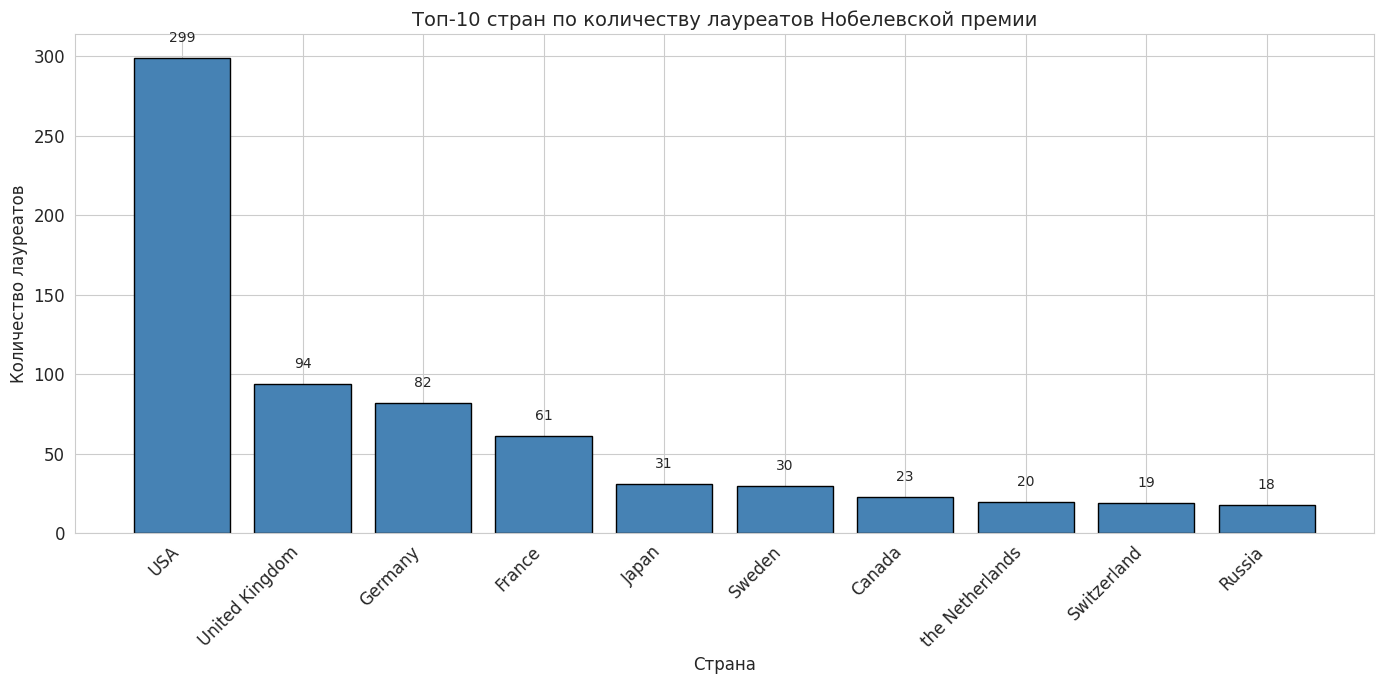

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12

top_countries = country_counts_sorted[:10]
countries_names = [r['country'] for r in top_countries]
countries_counts = [r['count'] for r in top_countries]

plt.figure(figsize=(14, 7))
plt.bar(countries_names, countries_counts, color='steelblue', edgecolor='black')

plt.title('Топ-10 стран по количеству лауреатов Нобелевской премии', fontsize=14)
plt.xlabel('Страна', fontsize=12)
plt.ylabel('Количество лауреатов', fontsize=12)

plt.xticks(rotation=45, ha='right')

for i, count in enumerate(countries_counts):
    plt.text(i, count + 10, str(count), ha='center', fontsize=10)

plt.tight_layout()
plt.show()

Анализ показывает, что распределение лауреатов по странам крайне неравномерно: США (299 из 1000) опережает Великобританию (94) более чем в 3 раза. На топ-3 страны приходится 475 лауреатов, то есть почти половина всех награждённых. Оставшиеся страны мира дают лишь единичных лауреатов, что говорит о сильной концентрации научной деятельности в узком кругу государств.

In [7]:
# теперь посмотрим на распределение по категория для стран, попавших в топ 3

top_3_countries = [r['country'] for r in country_counts_sorted[:3]]

print(f"анализ по категориям для топ-3 стран: {top_3_countries}")
print()

for country in top_3_countries:
    print(f"\n{country}")

    country_laureates = filter_by_condition(persons_only, 'country_birth', country)

    all_prizes = []
    for laureate in country_laureates:
        if 'prizes_relevant' in laureate and laureate['prizes_relevant']:
            all_prizes.extend(laureate['prizes_relevant'])

    category_groups = group_by(all_prizes, ['category_en'])

    category_counts = []
    for category, prizes in category_groups.items():
        cat_name = category[0]
        if cat_name is not None:
            category_counts.append({
                'category': cat_name,
                'count': len(prizes)
            })

    category_counts_sorted = sorted(category_counts, key=lambda x: x['count'], reverse=True)

    print(f"{'категория':<30} {'количество призов':<20}")
    print("-" * 50)
    for record in category_counts_sorted:
        print(f"{record['category']:<30} {record['count']:<20}")

анализ по категориям для топ-3 стран: ['USA', 'United Kingdom', 'Germany']


USA
категория                      количество призов   
--------------------------------------------------
Physiology or Medicine         85                  
Physics                        72                  
Chemistry                      60                  
Economic Sciences              56                  
Peace                          19                  
Literature                     10                  

United Kingdom
категория                      количество призов   
--------------------------------------------------
Chemistry                      27                  
Physiology or Medicine         25                  
Physics                        25                  
Economic Sciences              7                   
Literature                     6                   
Peace                          5                   

Germany
категория                      количество призов   
------------

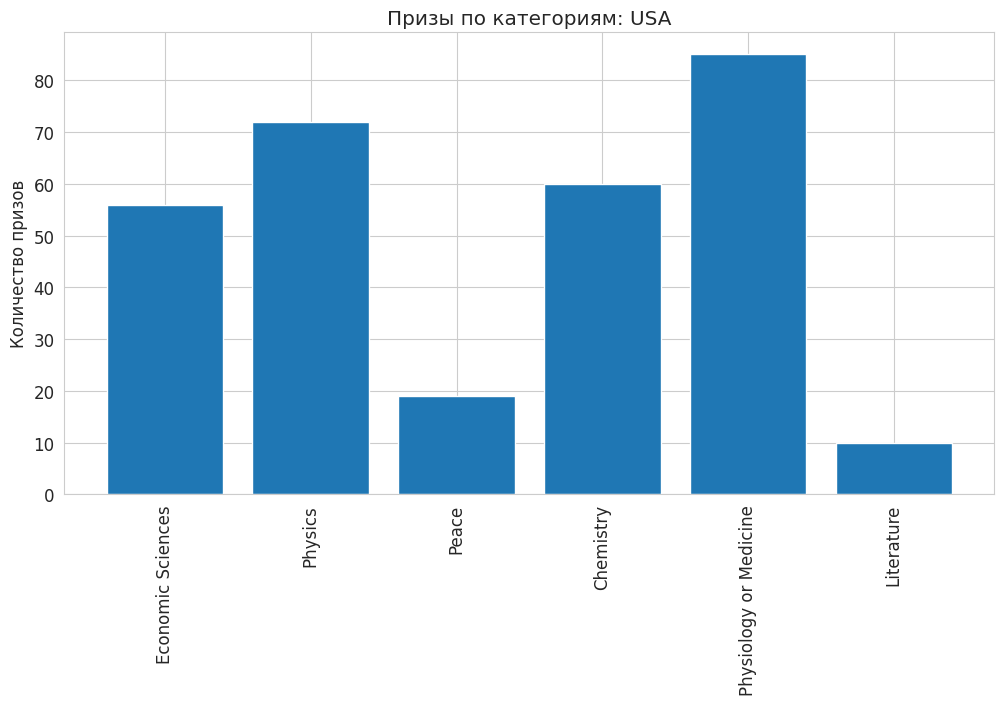

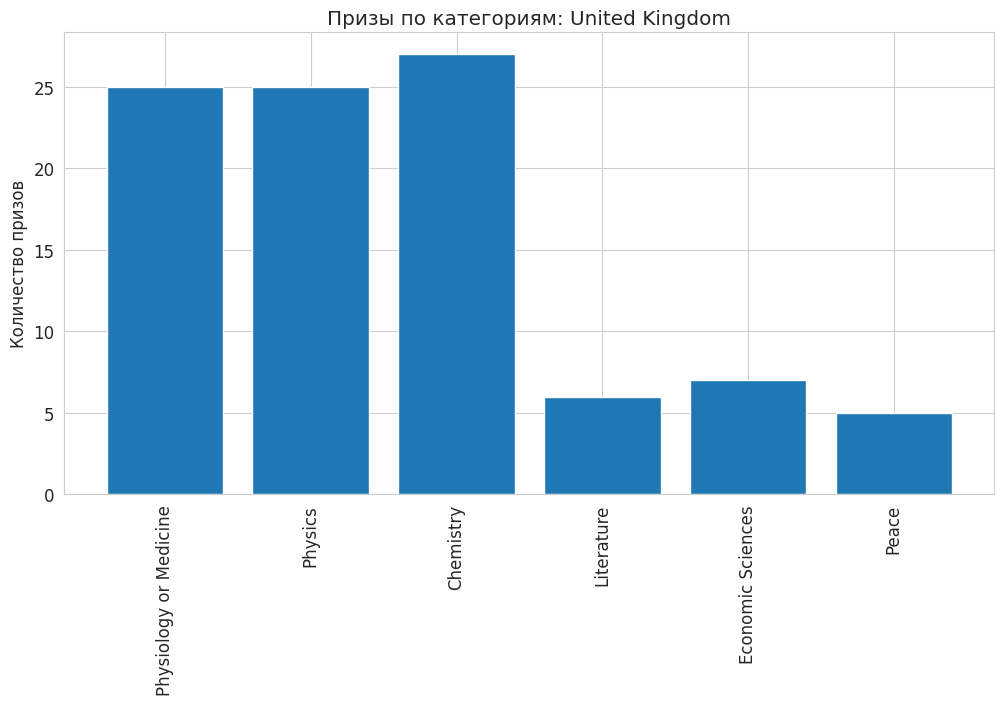

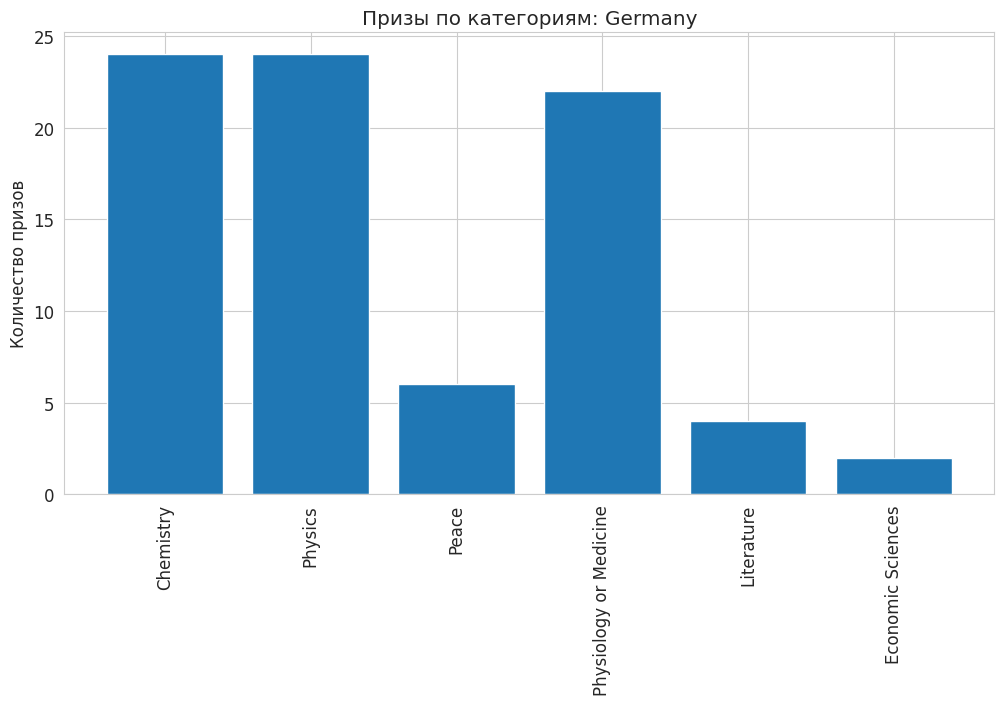

In [8]:
# для каждой страны из топ-3 сделаю отдельный график по категориям
for country in top_3_countries:
    country_laureates = filter_by_condition(persons_only, 'country_birth', country)

    prizes = []
    for laureate in country_laureates:
        if laureate['prizes_relevant']:
            prizes.extend(laureate['prizes_relevant'])

    groups = group_by(prizes, ['category_en'])

    cats = []
    nums = []
    for category, group in groups.items():
        if category[0] is not None:
            cats.append(category[0])
            nums.append(len(group))

    plt.figure()
    plt.bar(cats, nums)
    plt.title('Призы по категориям: ' + country)
    plt.ylabel('Количество призов')
    plt.xticks(rotation=90)
    plt.show()

США лидируют во всех категориях, но самый заметный разрыв в экономических науках: 56 премий против 7 у Великобритании и 2 у Германии, то есть эта категория почти полностью "американская". Великобритания и Германия, напротив, имеют похожее почти одинаковое количество наград в классических естественных науках (химия, физика, медицина — по 22–27 премий у каждой).

# 2.2 Возраст при награждении
**Вопросы для анализа:**
- Какой средний возраст лауреатов при получении первого приза?
- Различается ли возраст по категориям?
- Есть ли разница между средним и медианным возрастом?

Что буду делать:
1. Для каждого лауреата найду год первого приза
2. Вычислю возраст = год_приза - год_рождения
3. Посчитаю статистику (среднее, медиана)
4. Сгруппирую по категориям

In [9]:
def calculate_age_at_first_prize(laureate):
    if 'birth_year' not in laureate or laureate['birth_year'] is None:
        return None

    if 'prizes_relevant' not in laureate or not laureate['prizes_relevant']:
        return None

    prize_years = [p['award_year'] for p in laureate['prizes_relevant']
                   if 'award_year' in p and p['award_year'] is not None]

    if not prize_years:
        return None

    first_prize_year = min(prize_years)

    age = first_prize_year - laureate['birth_year']

    return age


for laureate in persons_only:
    laureate['age_at_first_prize'] = calculate_age_at_first_prize(laureate)

persons_with_age = [r for r in persons_only if r.get('age_at_first_prize') is not None]

print(f"лауреатов с известным возрастом при первом призе: {len(persons_with_age)}")
print()

mean_age = calculate_mean(persons_with_age, 'age_at_first_prize')
median_age = calculate_median(persons_with_age, 'age_at_first_prize')

print(f"статистика возраста при первом призе:")
print(f"средний возраст: {mean_age:.2f} лет")
print(f"медианный возраст: {median_age:.2f} лет")
print(f"разница: {abs(mean_age - median_age):.2f} лет")

лауреатов с известным возрастом при первом призе: 1000

статистика возраста при первом призе:
средний возраст: 60.61 лет
медианный возраст: 61.00 лет
разница: 0.39 лет


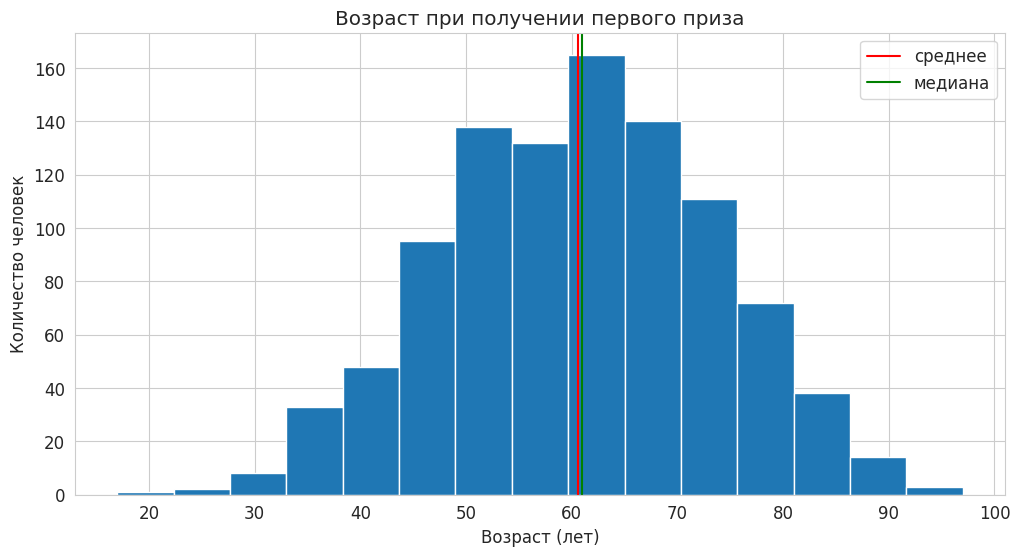

In [10]:
# возраст при первом призе
ages = []
for r in persons_with_age:
    ages.append(r['age_at_first_prize'])

plt.hist(ages, bins=15)
plt.axvline(mean_age, color='red', label='среднее')
plt.axvline(median_age, color='green', label='медиана')
plt.legend()
plt.title('Возраст при получении первого приза')
plt.xlabel('Возраст (лет)')
plt.ylabel('Количество человек')
plt.show()

Средний возраст получения первого приза — 60.6 лет, медианный — 61 год: разница всего 0.4 года, а гистограмма показывает почти симметричную форму с пиком в 60–65 лет. Значит, типичный нобелевский лауреат получает премию ближе к пенсионному возрасту, а очень молодые и очень пожилые награждённые — скорее исключения.

In [11]:
# посмотрим, как возраст различается по категориям премий
age_by_category = []

for laureate in persons_with_age:
    prizes = laureate['prizes_relevant']
    first_prize = min(prizes, key=lambda p: p.get('award_year', 9999))

    category = first_prize.get('category_en')
    age = laureate['age_at_first_prize']

    if category and age is not None:
        age_by_category.append({
            'category': category,
            'age': age
        })

category_groups = group_by(age_by_category, ['category'])

print("возраст при первом призе по категориям:")
print(f"{'категория':<25} {'кол-во':<8} {'средний':<10} {'медиана':<10}")
print("-" * 50)

category_stats = []

for category, records in category_groups.items():
    cat_name = category[0]
    if cat_name is None:
        continue

    ages = [r['age'] for r in records]
    count = len(ages)
    mean_val = sum(ages) / count if count > 0 else 0

    sorted_ages = sorted(ages)
    mid = count // 2
    if count % 2 == 0:
        median_val = (sorted_ages[mid - 1] + sorted_ages[mid]) / 2
    else:
        median_val = sorted_ages[mid]

    category_stats.append({
        'category': cat_name,
        'count': count,
        'mean': mean_val,
        'median': median_val
    })

category_stats_sorted = sorted(category_stats, key=lambda x: x['mean'])

for record in category_stats_sorted:
    print(f"{record['category']:<25} {record['count']:<8} {record['mean']:<10.2f} {record['median']:<10.2f}")

возраст при первом призе по категориям:
категория                 кол-во   средний    медиана   
--------------------------------------------------
Physics                   230      57.79      56.00     
Physiology or Medicine    235      59.02      58.00     
Chemistry                 199      59.43      58.00     
Peace                     112      60.97      62.00     
Literature                123      65.04      67.00     
Economic Sciences         101      67.21      67.00     


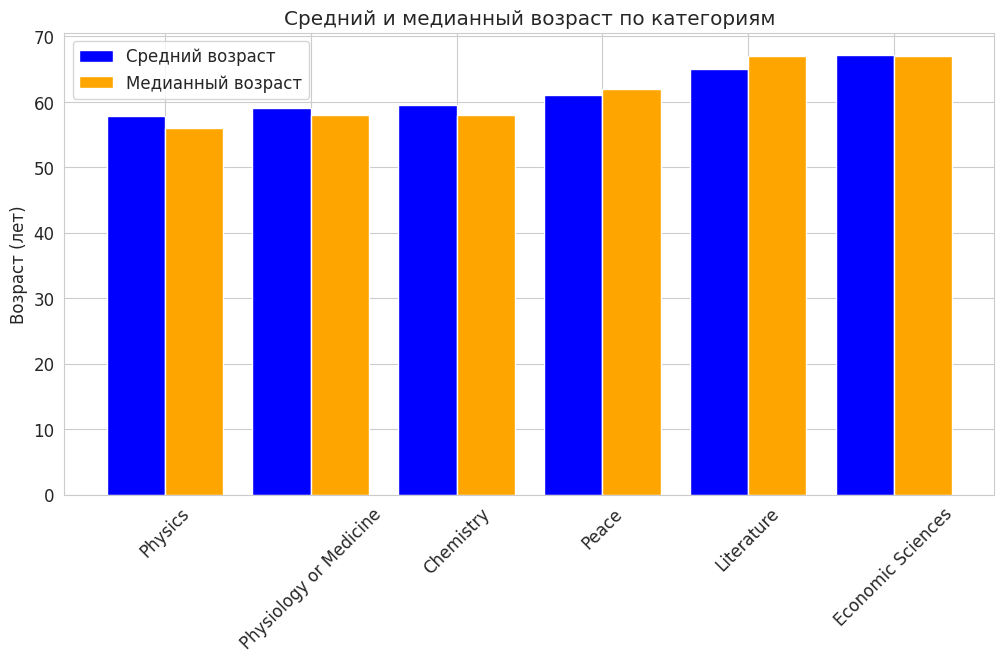

In [12]:
# сравним средний и медианный возраст по категориям
cat_names = []
cat_means = []
cat_medians = []
for r in category_stats_sorted:
    cat_names.append(r['category'])
    cat_means.append(r['mean'])
    cat_medians.append(r['median'])

x = range(len(cat_names))

plt.bar(x, cat_means, width=0.4, label='Средний возраст', color='blue')
plt.bar([i + 0.4 for i in x], cat_medians, width=0.4, label='Медианный возраст', color='orange')
plt.xticks([i + 0.2 for i in x], cat_names, rotation=45)
plt.ylabel('Возраст (лет)')
plt.title('Средний и медианный возраст по категориям')
plt.legend()
plt.show()

Категории четко делятся на две группы: "молодые" естественные науки (физика — 57.8, медицина — 59.0, химия — 59.4) и "возрастные" гуманитарные и социальные области (литература — 65.0, экономика — 67.2; премия мира — 61.0). Разрыв между физикой и экономикой достигает примерно 9 лет. Вероятно, в точных науках премию дают за конкретное открытие, сделанное в середине карьеры, тогда как в литературе и экономике награждают совокупный жизненный вклад, на который нужно больше времени. Интересно, что в науках среднее выше медианы, а в премии мира и литературе — наоборот ниже, то есть там встречаются заметные молодые лауреаты, тянущие среднее вниз.

# 2.3 Гендерное распределение
Вопросы для анализа:
- Как менялось количество женщин-лауреатов по десятилетиям?
- Как распределяются женщины-лауреаты по категориям премий?
- В какой категории больше всего женщин-лауреатов в целом и в последние десятилетия?

Чего сделаю:
1. Отфильтрую только лауреатов-женщин (`gender == 'female'`).
2. Для каждой женщины определю десятилетие её *первой* награды (чтобы не считать одного человека дважды, если она получала премию несколько раз).
3. Сгруппирую данные по десятилетиям и по категориям.

In [13]:
def get_decade(year):
    if year is None:
        return None
    return (year // 10) * 10

female_laureates = filter_by_condition(persons_only, 'gender', 'female')
print(f"всего женщин-лауреатов: {len(female_laureates)}")
print()

female_prizes_data = []

for laureate in female_laureates:
    prizes = laureate.get('prizes_relevant', [])
    if not prizes:
        continue

    first_prize = min(prizes, key=lambda p: p.get('award_year', 9999))

    award_year = first_prize.get('award_year')
    category = first_prize.get('category_en')

    if award_year and category:
        female_prizes_data.append({
            'decade': get_decade(award_year),
            'category': category
        })

decade_groups = group_by(female_prizes_data, ['decade'])

decade_counts = []
for decade, records in decade_groups.items():
    decade_val = decade[0]
    if decade_val is not None:
        decade_counts.append({
            'decade': f"{decade_val}-е",
            'count': len(records)
        })

decade_counts_sorted = sorted(decade_counts, key=lambda x: x['decade'])

print("количество женщин-лауреатов по десятилетиям (по первой награде):")
print(f"{'десятилетие':<15} {'количество':<12}")
print("-" * 50)
for record in decade_counts_sorted:
    print(f"{record['decade']:<15} {record['count']:<12}")

всего женщин-лауреатов: 69

количество женщин-лауреатов по десятилетиям (по первой награде):
десятилетие     количество  
--------------------------------------------------
1900-е          3           
1920-е          2           
1930-е          3           
1940-е          3           
1960-е          3           
1970-е          4           
1980-е          4           
1990-е          7           
2000-е          11          
2010-е          13          
2020-е          16          


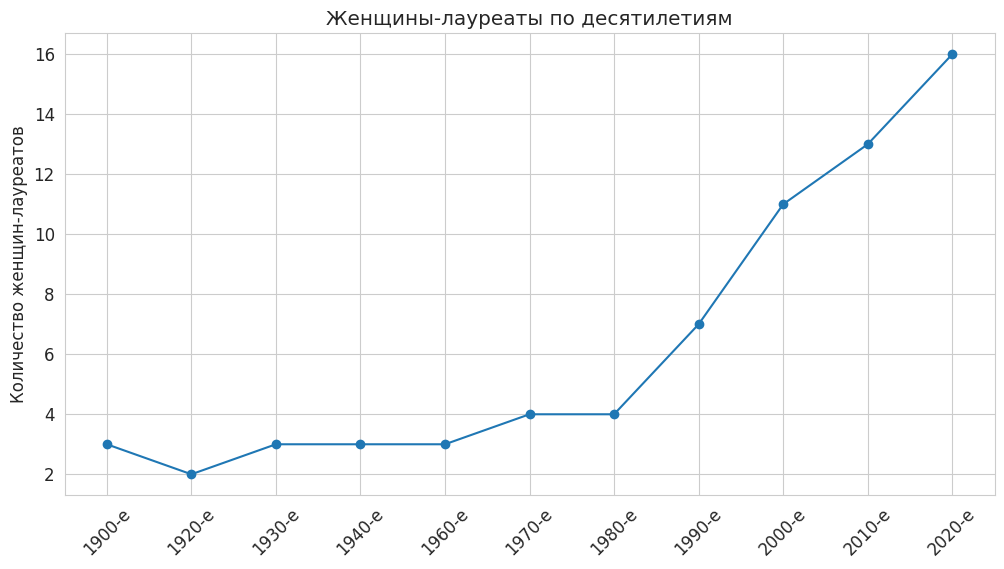

In [14]:
# как менялось количество женщин-лауреатов по десятилетиям
decades = []
counts = []
for r in decade_counts_sorted:
    decades.append(r['decade'])
    counts.append(r['count'])

plt.plot(decades, counts, marker='o')
plt.grid(True)
plt.title('Женщины-лауреаты по десятилетиям')
plt.ylabel('Количество женщин-лауреатов')
plt.xticks(rotation=45)
plt.show()

Женщин среди лауреатов всего 69 из 1000, и первые 80 лет истории премии их количество практически не менялось: 2–4 награждённых за десятилетие, а в 1950-е не было ни одной. Перелом наступает в 1990-е: с 7 лауреаток показатель растёт каждое десятилетие и в 2020-х достигает рекордных 16 — больше, чем за всю первую половину XX века вместе взятую. То есть, рост представленности женщин — явление исключительно последних 30 лет.

In [15]:
# анализ по категориям
category_groups = group_by(female_prizes_data, ['category'])

category_counts = []
for category, records in category_groups.items():
    cat_name = category[0]
    if cat_name is not None:
        category_counts.append({
            'category': cat_name,
            'count': len(records)
        })

category_counts_sorted = sorted(category_counts, key=lambda x: x['count'], reverse=True)

print("\nраспределение женщин-лауреатов по категориям (всего):")
print(f"{'категория':<30} {'количество наград':<20}")
print("-" * 50)
for record in category_counts_sorted:
    print(f"{record['category']:<30} {record['count']:<20}")

recent_female_prizes = [p for p in female_prizes_data if p['decade'] is not None and p['decade'] >= 1990]
recent_category_groups = group_by(recent_female_prizes, ['category'])

recent_category_counts = []
for category, records in recent_category_groups.items():
    cat_name = category[0]
    if cat_name is not None:
        recent_category_counts.append({
            'category': cat_name,
            'count': len(records)
        })

recent_category_counts_sorted = sorted(recent_category_counts, key=lambda x: x['count'], reverse=True)

print("\nраспределение женщин-лауреатов по категориям (с 1990 года):")
print(f"{'категория':<30} {'количество наград':<20}")
print("-" * 50)
for record in recent_category_counts_sorted:
    print(f"{record['category']:<30} {record['count']:<20}")


распределение женщин-лауреатов по категориям (всего):
категория                      количество наград   
--------------------------------------------------
Peace                          21                  
Literature                     19                  
Physiology or Medicine         14                  
Chemistry                      7                   
Physics                        5                   
Economic Sciences              3                   

распределение женщин-лауреатов по категориям (с 1990 года):
категория                      количество наград   
--------------------------------------------------
Peace                          14                  
Literature                     13                  
Physiology or Medicine         9                   
Chemistry                      5                   
Physics                        3                   
Economic Sciences              3                   


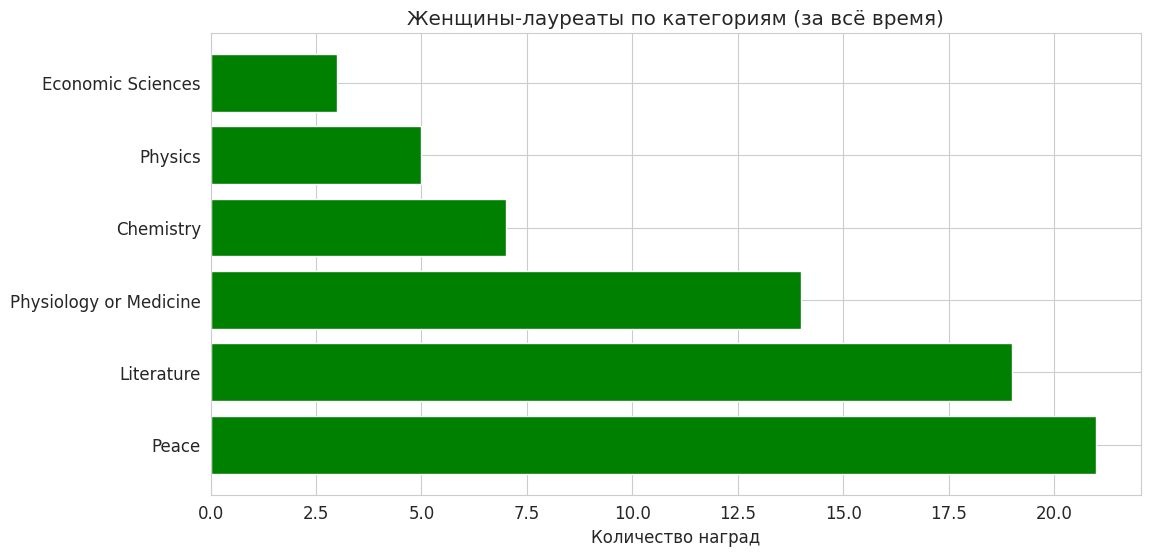

In [16]:
# в каких категориях больше всего женщин
cats = []
nums = []
for r in category_counts_sorted:
    cats.append(r['category'])
    nums.append(r['count'])

plt.barh(cats, nums, color='green')
plt.title('Женщины-лауреаты по категориям (за всё время)')
plt.xlabel('Количество наград')
plt.show()

Женские премии сконцентрированы в "неестественнонаучных" категориях: Peace (21) и Literature (19) суммарно дают около 60% всех женских наград, тогда как в Physics их всего 5, а в Economic Sciences — 3. В периоде с 1990 года лидерство Peace сохраняется (14), но примечательно другое: большинство женских премий в науках вручено именно после 1990-х — 5 из 7 в Chemistry, 9 из 14 в Medicine и все 3 в Economic Sciences. Значит, в гуманитарных сферах женщин стали признавать раньше, а репрезентация в естественных науках началась поздно.